# Final evaluation and model artifact

Run with **Kernel -> Restart & Run All**. Requires `data/creditcard.csv` and `data/oof_predictions.csv`
(from notebook 01). The decisions in section 0 are fixed **before** the test set is touched.
The test set is scored exactly once, in section 5. If you change anything after looking at those
results, the test set has become a tuning set and its numbers are no longer honest.

## 0. Settings fixed before looking at the test set

In [1]:
import os, json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
import xgboost, sklearn
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, log_loss
from xgboost import XGBClassifier

REVIEW_COST = 5.0        # R: cost of one analyst review ($)
EXTRA_PER_MISS = 25.0    # extra loss per missed fraud ($): chargeback fee, customer harm
HIGH_RISK_P = 0.90       # calibrated probability at or above which a transaction is escalated
MODEL_VERSION = "v1"

# The notebook stops if the data is not what we expect
EXPECTED_SHAPE = (283726, 31)
EXPECTED_SPLIT_FRAUDS = (284, 94, 95)
EXPECTED_CV = (226980, 378)

os.makedirs("../figures", exist_ok=True)
os.makedirs("../models", exist_ok=True)

## 1. Data: same dedup, split and scaling as notebook 01

In [2]:
df = pd.read_csv("../data/creditcard.csv").drop_duplicates().reset_index(drop=True)
assert df.shape == EXPECTED_SHAPE, df.shape
X, y = df.drop(columns="Class"), df["Class"]

X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()

for d in (X_train, X_val, X_test):
    d["Amount"] = np.log1p(d["Amount"])
cols = ["Time", "Amount"]
scaler = StandardScaler().fit(X_train[cols])       # fit on TRAIN only, as in notebook 01
for d in (X_train, X_val, X_test):
    d[cols] = scaler.transform(d[cols])

frauds = (int(y_train.sum()), int(y_val.sum()), int(y_test.sum()))
assert frauds == EXPECTED_SPLIT_FRAUDS, frauds
X_cv = pd.concat([X_train, X_val]); y_cv = pd.concat([y_train, y_val])
assert (len(X_cv), int(y_cv.sum())) == EXPECTED_CV
features = list(X_train.columns)
print("ok:", X_train.shape, X_val.shape, X_test.shape, "frauds", frauds)

ok: (170235, 30) (56745, 30) (56746, 30) frauds (284, 94, 95)


## 2. Out-of-fold predictions from notebook 01 (must match this split exactly)

In [3]:
oof = pd.read_csv("../data/oof_predictions.csv", index_col=0)
assert np.array_equal(oof.index.values, X_cv.index.values), "OOF file does not match the current split"
assert np.array_equal(oof["y"].values, y_cv.values)
s_oof, y_oof, amt_oof = oof["avg"].values, oof["y"].values, oof["amount"].values
print(oof.shape, int(y_oof.sum()))

(226980, 5) 378


## 3. Calibrator and decision rules (fitted on out-of-fold data only)

In [4]:
EPS = 1e-6
def logit(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p)).reshape(-1, 1)

platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(s_oof), y_oof)
def calibrate(s):
    return np.clip(platt.predict_proba(logit(s))[:, 1], EPS, 1 - EPS)
p_oof = calibrate(s_oof)
print("Platt slope %.3f, intercept %.3f" % (platt.coef_[0][0], platt.intercept_[0]))

def cost(flag, y_, amt_, R=REVIEW_COST, fixed=EXTRA_PER_MISS):
    missed = (~flag) & (y_ == 1)
    return (amt_[missed] + fixed).sum() + R * flag.sum()

def assign_tier(p, amount):
    # low: expected loss below one review -> approve; medium: review queue; high: escalate
    ratio = p * (amount + EXTRA_PER_MISS) / REVIEW_COST
    return np.where(p >= HIGH_RISK_P, "high", np.where(ratio >= 1, "medium", "low"))

def tier_table(tier, y_):
    t = pd.DataFrame({"tier": tier, "y": y_}).groupby("tier").agg(n=("y", "size"), frauds=("y", "sum"))
    t["fraud_rate"] = (t["frauds"] / t["n"]).round(4)
    return t.reindex(["low", "medium", "high"])

# comparison rule: one global threshold, chosen on OOF data
thresholds = np.logspace(-4, -0.01, 300)
GLOBAL_T = float(thresholds[int(np.argmin([cost(p_oof >= t, y_oof, amt_oof) for t in thresholds]))])
print("global threshold chosen on OOF data: %.4f" % GLOBAL_T)       # about 0.016
print(tier_table(assign_tier(p_oof, amt_oof), y_oof))

Platt slope 0.790, intercept -0.038
global threshold chosen on OOF data: 0.0169
             n  frauds  fraud_rate
tier                              
low     226356      62      0.0003
medium     401      96      0.2394
high       223     220      0.9865


## 4. Retrain on all train + validation data (same recipes as the cross-validation)

In [5]:
def build_keras(n_features, neg, pos):
    m = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(0.3),
        keras.layers.Dense(32, activation="relu"), keras.layers.Dropout(0.3),
        keras.layers.Dense(1, activation="sigmoid",
                           bias_initializer=keras.initializers.Constant(np.log(pos / neg))),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return m

Xa, ya = X_cv.values, y_cv.values
xgb_final = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                          eval_metric="aucpr", n_jobs=-1, random_state=42).fit(Xa, ya)

tf.keras.utils.set_random_seed(1)
neg, pos = np.bincount(ya)
keras_final = build_keras(Xa.shape[1], neg, pos)
keras_final.fit(Xa, ya, batch_size=2048, epochs=60, verbose=0)

lr_final = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xa, ya)
print("models trained")

models trained


## 5. Score the test set (once)

Nothing below this line may change a decision made above it.

In [6]:
Xt, yt = X_test.values, y_test.values
amt_test = df.loc[X_test.index, "Amount"].values        # original dollars

p_lr = lr_final.predict_proba(Xt)[:, 1]
p_xgb = xgb_final.predict_proba(Xt)[:, 1]
p_keras = keras_final.predict(Xt, batch_size=4096, verbose=0).ravel()
s_test = (p_xgb + p_keras) / 2
p_test = calibrate(s_test)

def boot_ap_ci(p, n=500):
    rng = np.random.default_rng(0)                       # same resamples for every model
    aps = []
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        aps.append(average_precision_score(yt[i], p[i]))
    return np.percentile(aps, [2.5, 97.5])

print("TEST PR-AUC (95 frauds, so expect wide intervals)")
test_ap = {}
for name, p in [("LogReg", p_lr), ("XGBoost", p_xgb), ("Keras", p_keras), ("Average", s_test)]:
    ap = average_precision_score(yt, p); lo, hi = boot_ap_ci(p)
    test_ap[name] = float(ap)
    print(f"  {name:8s} {ap:.3f}   95% CI {lo:.3f} to {hi:.3f}")

TEST PR-AUC (95 frauds, so expect wide intervals)
  LogReg   0.715   95% CI 0.589 to 0.808
  XGBoost  0.871   95% CI 0.802 to 0.933
  Keras    0.855   95% CI 0.788 to 0.915
  Average  0.886   95% CI 0.827 to 0.944


### Calibration on the test set

In [7]:
bins = [0, 0.001, 0.01, 0.05, 0.2, 0.5, 0.8, 1.0001]
tab = pd.DataFrame({"raw": s_test, "calibrated": p_test, "y": yt})
tab["bin"] = pd.cut(tab["calibrated"], bins, right=False)
print(tab.groupby("bin", observed=True).agg(n=("y", "size"), frauds=("y", "sum"),
      mean_calibrated=("calibrated", "mean"), observed_rate=("y", "mean")).round(4))
print("log loss  raw: %.5f   calibrated: %.5f" % (
      log_loss(yt, np.clip(s_test, EPS, 1 - EPS)), log_loss(yt, p_test)))

                   n  frauds  mean_calibrated  observed_rate
bin                                                         
[0.0, 0.001)   53972       5           0.0001         0.0001
[0.001, 0.01)   2479       5           0.0027         0.0020
[0.01, 0.05)     194       2           0.0193         0.0103
[0.05, 0.2)       20       5           0.0776         0.2500
[0.2, 0.5)         6       5           0.3816         0.8333
[0.5, 0.8)        24      22           0.6316         0.9167
[0.8, 1.0)        51      51           0.9560         1.0000
log loss  raw: 0.00250   calibrated: 0.00233


### Cost and risk tiers on the test set

In [8]:
def per_txn_cost(flag, y_, amt_, R=REVIEW_COST, fixed=EXTRA_PER_MISS):
    return np.where(flag, R, np.where(y_ == 1, amt_ + fixed, 0.0))

tier_test = assign_tier(p_test, amt_test)
rules = {"flag nothing": np.zeros(len(yt), bool),
         f"global t={GLOBAL_T:.4f}": p_test >= GLOBAL_T,
         "amount-aware tiers": tier_test != "low"}
base = cost(rules["flag nothing"], yt, amt_test)
rows = []
for name, flag in rules.items():
    c = cost(flag, yt, amt_test); tp = int((flag & (yt == 1)).sum())
    rows.append(dict(rule=name, cost=round(c), saved_pct=round(100 * (base - c) / base, 1),
                     flagged=int(flag.sum()), precision=round(tp / max(flag.sum(), 1), 3),
                     recall=round(tp / yt.sum(), 3)))
test_costs = pd.DataFrame(rows)
print(test_costs.to_string(index=False))

# is the amount-aware advantage over the global threshold distinguishable from noise?
diff = (per_txn_cost(rules[f"global t={GLOBAL_T:.4f}"], yt, amt_test)
        - per_txn_cost(rules["amount-aware tiers"], yt, amt_test))
rng = np.random.default_rng(0)
boot = [diff[rng.integers(0, len(diff), len(diff))].sum() for _ in range(1000)]
print("amount-aware saves $%.0f vs global (95%% CI $%.0f to $%.0f)" % (
      diff.sum(), *np.percentile(boot, [2.5, 97.5])))

print(); print(tier_table(tier_test, yt))

              rule  cost  saved_pct  flagged  precision  recall
      flag nothing 15348        0.0        0      0.000   0.000
   global t=0.0169  3236       78.9      196      0.434   0.895
amount-aware tiers  2347       84.7      152      0.546   0.874
amount-aware saves $889 vs global (95% CI $43 to $2474)

            n  frauds  fraud_rate
tier                             
low     56594      12      0.0002
medium    111      42      0.3784
high       41      41      1.0000


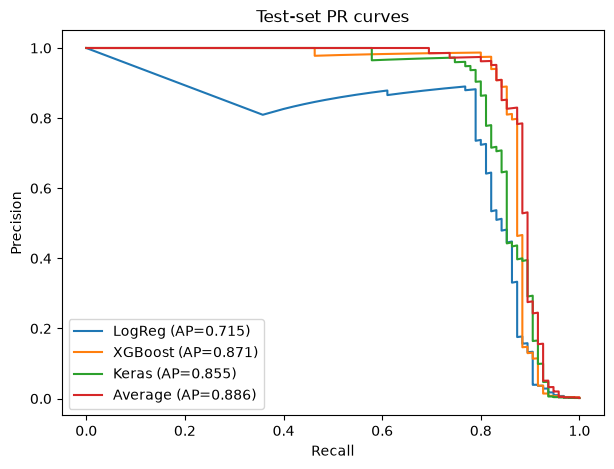

In [9]:
plt.figure(figsize=(7, 5))
for name, p in [("LogReg", p_lr), ("XGBoost", p_xgb), ("Keras", p_keras), ("Average", s_test)]:
    prec, rec, _ = precision_recall_curve(yt, p)
    plt.plot(rec, prec, label=f"{name} (AP={test_ap[name]:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("Test-set PR curves")
plt.savefig("../figures/test_pr_curves.png", dpi=150); plt.show()

## 6. Save the artifact

In [10]:
ART = f"../models/fraud_{MODEL_VERSION}"
os.makedirs(ART, exist_ok=True)
xgb_final.save_model(f"{ART}/xgb.json")
keras_final.save(f"{ART}/keras.keras")
joblib.dump(scaler, f"{ART}/scaler.joblib")
joblib.dump(platt, f"{ART}/platt.joblib")

config = {
    "version": MODEL_VERSION,
    "features": features,
    "preprocessing": "Amount -> log1p; then StandardScaler on [Time, Amount]",
    "score": "mean of XGBoost and Keras probabilities, then Platt calibration",
    "review_cost": REVIEW_COST, "extra_per_miss": EXTRA_PER_MISS, "high_risk_p": HIGH_RISK_P,
    "global_threshold": GLOBAL_T,
    "trained_on": {"rows": int(len(X_cv)), "frauds": int(y_cv.sum())},
    "test_pr_auc": test_ap,
    "test_cost_table": test_costs.to_dict(orient="records"),
    "libraries": {"tensorflow": tf.__version__, "xgboost": xgboost.__version__,
                  "scikit-learn": sklearn.__version__},
}
json.dump(config, open(f"{ART}/config.json", "w"), indent=2)
print(sorted(os.listdir(ART)))

['config.json', 'keras.keras', 'platt.joblib', 'scaler.joblib', 'xgb.json']


## 7. Reload from disk and check it reproduces the in-memory results from raw transactions

In [11]:
xgb_l = XGBClassifier(); xgb_l.load_model(f"{ART}/xgb.json")
keras_l = keras.models.load_model(f"{ART}/keras.keras")
scaler_l = joblib.load(f"{ART}/scaler.joblib")
platt_l = joblib.load(f"{ART}/platt.joblib")
cfg = json.load(open(f"{ART}/config.json"))

def score_raw(raw):
    # raw: DataFrame with the original columns Time, V1..V28, Amount (Amount in dollars)
    amount = raw["Amount"].values
    x = raw[cfg["features"]].copy()
    x["Amount"] = np.log1p(x["Amount"])
    x[["Time", "Amount"]] = scaler_l.transform(x[["Time", "Amount"]])
    v = x.values
    s = (xgb_l.predict_proba(v)[:, 1] + keras_l.predict(v, batch_size=4096, verbose=0).ravel()) / 2
    p = np.clip(platt_l.predict_proba(logit(s))[:, 1], EPS, 1 - EPS)
    ratio = p * (amount + cfg["extra_per_miss"]) / cfg["review_cost"]
    tier = np.where(p >= cfg["high_risk_p"], "high", np.where(ratio >= 1, "medium", "low"))
    return pd.DataFrame({"fraud_probability": p, "expected_loss_ratio": ratio, "tier": tier}, index=raw.index)

n = 2000
check = score_raw(df.loc[X_test.index[:n], cfg["features"]])
assert np.allclose(check["fraud_probability"].values, p_test[:n], atol=1e-4), "reloaded model differs"
assert (check["tier"].values == tier_test[:n]).all()
print("artifact reproduces the in-memory scores and tiers on", n, "raw test transactions")
print(check.head())

artifact reproduces the in-memory scores and tiers on 2000 raw test transactions
        fraud_probability  expected_loss_ratio tier
65102            0.000267             0.003043  low
270423           0.000018             0.000096  low
158248           0.000032             0.000183  low
46951            0.000197             0.007509  low
212028           0.000018             0.000102  low
